<a href="https://colab.research.google.com/github/IsaacMHLK/Makro-sales-time-series-analysis/blob/main/Sale_time_series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Makro Sales: Time-Series Analysis & Forecasting

Exploring Makro retail sales data and forecasting future monthly sales with AR, MA, ARIMA and SARIMA models.


Import libraries

In [75]:
#imports all necessary python libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


Loading the Dataset into sales_df then preview the dataframe

In [76]:
#loads the sales dataset and stores it in the sales_df variable and preview
sales_df = pd.read_csv('/content/sales.csv', index_col=0)
sales_df.head(5)

,Row ID,Order ID,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Order_Date
0,1,CA-2017-152156,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,08/11/2017
1,2,CA-2017-152156,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,08/11/2017
2,3,CA-2017-138688,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,12/06/2017
3,4,US-2016-108966,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,11/10/2016
4,5,US-2016-108966,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,11/10/2016


Inspecting the data, Shape and data types, missing values, and columns using the Info method.

In [77]:
sales_df.shape

(9800, 18)

In [78]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Ship Date      9800 non-null   object 
 3   Ship Mode      9800 non-null   object 
 4   Customer ID    9800 non-null   object 
 5   Customer Name  9800 non-null   object 
 6   Segment        9800 non-null   object 
 7   Country        9800 non-null   object 
 8   City           9800 non-null   object 
 9   State          9800 non-null   object 
 10  Postal Code    9789 non-null   float64
 11  Region         9800 non-null   object 
 12  Product ID     9800 non-null   object 
 13  Category       9800 non-null   object 
 14  Sub-Category   9800 non-null   object 
 15  Product Name   9800 non-null   object 
 16  Sales          9800 non-null   float64
 17  Order_Date     9800 non-null   object 
dtypes: float64(2)

## Data Cleaning and Preparation

From the info method above, it can be observed that there are 9800 rows, However, Postal Code has 9789 non-null rows, which indicate there might be missing values.

Check for missing Values

In [79]:
sales_df.isnull().sum()

,0
Row ID,0
Order ID,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0
State,0


Fill missing Values with 0

In [80]:
sales_df['Postal Code'] =sales_df['Postal Code'].fillna(0)

Check if missing values are filled

In [81]:
sales_df.isnull().sum()

,0
Row ID,0
Order ID,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0
State,0


Check for duplicates

In [82]:
sales_df.duplicated().sum()

np.int64(0)

convert order_date and Ssip Date to date object

In [83]:
sales_df['Order_Date'] = pd.to_datetime(sales_df['Order_Date'], format='%d/%m/%Y')

sales_df['Ship Date'] = pd.to_datetime(sales_df['Ship Date'],format='%d/%m/%Y')

check if dates are converted

In [84]:
print(sales_df[['Order_Date', 'Ship Date']].head(5))
print(sales_df[['Order_Date', 'Ship Date']].dtypes)

  Order_Date  Ship Date
0 2017-11-08 2017-11-11
1 2017-11-08 2017-11-11
2 2017-06-12 2017-06-16
3 2016-10-11 2016-10-18
4 2016-10-11 2016-10-18
Order_Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


Conclusion:
the unnamed column was removed, Order_date and Ship Date were converted to datetime datatype, missing values in Postal Code were filled with 0. the dataset is cleaned.

## Sales Exploration

### Total sales by state

Group sales by state, Preview then visualise using choropleth map. states will be changed to abbreviations for visualisation purposes.

In [85]:
#Groups sales by State
state_sales = (sales_df.groupby('State')['Sales'].sum().reset_index())
print(state_sales.sort_values(by='Sales', ascending=False).head(5))

           State        Sales
3     California  446306.4635
30      New York  306361.1470
41         Texas  168572.5322
45    Washington  135206.8500
36  Pennsylvania  116276.6500


In [86]:
#Temporarily rename the states into abbreviations in order to fit in the plot
state_abbreviations = {
    'Alabama': 'AL', 'Arizona': 'AZ', 'Arkansas': 'AR',
    'California': 'CA', 'Colorado': 'CO', 'Connecticut': 'CT',
    'Delaware': 'DE', 'Florida': 'FL', 'Georgia': 'GA',
    'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN',
    'Iowa': 'IA', 'Kansas': 'KS', 'Kentucky': 'KY',
    'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD',
    'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN',
    'Mississippi': 'MS', 'Missouri': 'MO', 'Montana': 'MT',
    'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH',
    'New Jersey': 'NJ', 'New Mexico': 'NM', 'New York': 'NY',
    'North Carolina': 'NC', 'North Dakota': 'ND', 'Ohio': 'OH',
    'Oklahoma': 'OK', 'Oregon': 'OR', 'Pennsylvania': 'PA',
    'Rhode Island': 'RI', 'South Carolina': 'SC',
    'South Dakota': 'SD', 'Tennessee': 'TN', 'Texas': 'TX',
    'Utah': 'UT', 'Vermont': 'VT', 'Virginia': 'VA',
    'Washington': 'WA', 'West Virginia': 'WV',
    'Wisconsin': 'WI', 'Wyoming': 'WY',
    'District of Columbia': 'DC'
}

state_sales['State_Code'] = state_sales['State'].map(state_abbreviations)

In [87]:
#plots the choropleth map of sales by state.
import plotly.express as px

fig = px.choropleth(state_sales, locations='State_Code', locationmode='USA-states', color='Sales', scope='usa',
    title='Total Sales by State/Province',
    color_continuous_scale='Reds')
fig.add_scattergeo(locations=state_sales['State_Code'], locationmode='USA-states', text=state_sales['State_Code'],
    mode='text', textfont=dict(size=8, color='black'), showlegend=False)
fig.show()

It can be observed that there is variation in the number of sales across each state. on the map, the darker the color, the more sales the state has.  The stongest performing state in terms of sales is Califonia, followed by New york, Texas then Washington. It can also be observed that some states have considerably week sales performance, North Dakota being the weekest performer amongst the states, followed by few other states including, West Virginia Maine, South Dakota, and Wyoming.

There is overall an uneven distribution of sales geograpphically. small states account for relatively high proportions while many account for small.

**Sales by region**

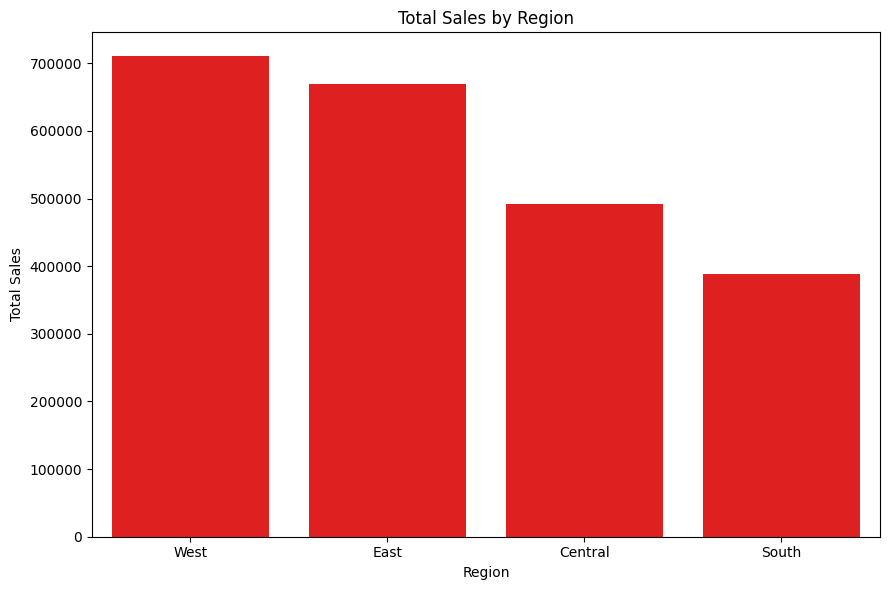

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64


In [88]:
#groups sales by region and plot a bar graph, with total sales per region
region_sales = (sales_df.groupby('Region')['Sales'].sum().sort_values(ascending=False))
plt.figure(figsize=(9, 6))
sns.barplot(x=region_sales.index,y=region_sales.values, color="red")
plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()
print(region_sales)

**Interpretation**

The west region seems to be making more sales than the rest of the regions. The South region makes the lowest sales. stock in the west region should never run short. an investigation into why the southern region is weak in sales need to be launched. customer engagement can improve and maintain sales in all regions.

**Sales by category**

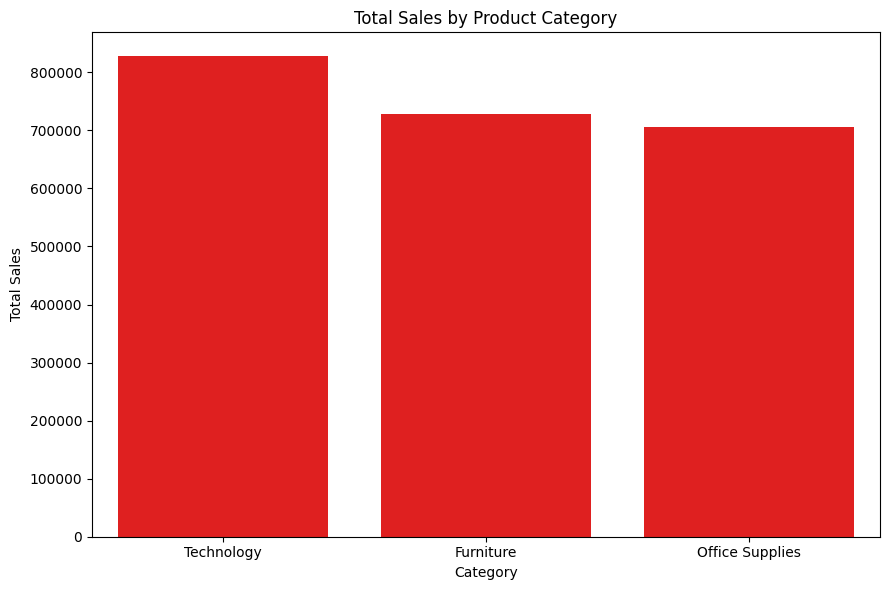

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64


In [89]:
#groups sales by category, plots a bar graph and total sales of each category
category_sales = (sales_df.groupby('Category')['Sales'].sum().sort_values(ascending=False))
plt.figure(figsize=(9, 6))
sns.barplot(x=category_sales.index, y=category_sales.values, color='red')
plt.title('Total Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()
print(category_sales)

**Interpretation**

Technology has the highest number of total sales. this indicate that Technology brings in more revenue and it is the important category. stock for this category should never be short and stock is always available. furniture and office supplies need to be investigated more in terms of pricing and whether promotions can result in more sales.

**Top 10 sales Cities**

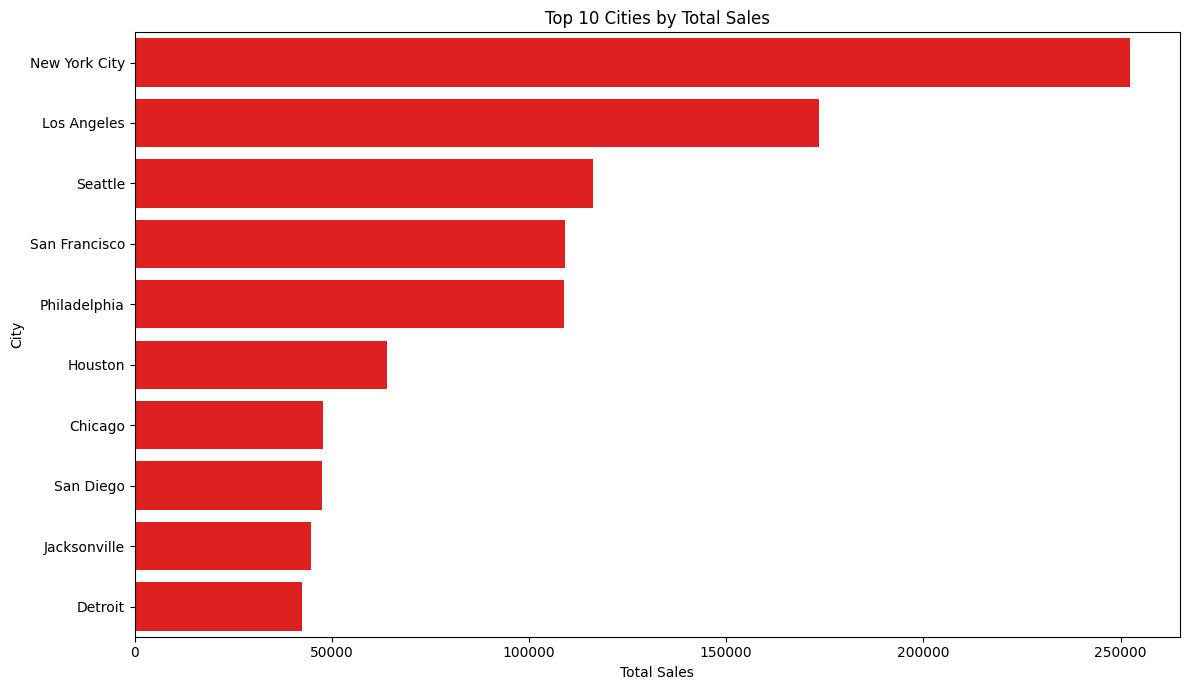

City
New York City    252462.5470
Los Angeles      173420.1810
Seattle          116106.3220
San Francisco    109041.1200
Philadelphia     108841.7490
Houston           63956.1428
Chicago           47820.1330
San Diego         47521.0290
Jacksonville      44713.1830
Detroit           42446.9440
Name: Sales, dtype: float64


In [90]:
#groups sales by city, plots a bar graph and show top 10 total sales in city
city_sales = (sales_df.groupby('City')['Sales'].sum().sort_values(ascending=False))
top_10_cities = city_sales.head(10)
plt.figure(figsize=(12, 7))
sns.barplot(x=top_10_cities.values, y=top_10_cities.index, color='red')
plt.title('Top 10 Cities by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('City')
plt.tight_layout()
plt.show()
print(city_sales.head(10))

**Interpretation**

these are the top 10 cities that contribute the most in Makro. the number city the brings in more sales is New Yock city. this may be due to density or popularity of the city. it is followed by Los Angeles. customer service and marketing in these cities should be a priority. however, investigation and the underperforming cities should be implemented to grow the sales. expansion in terms of stores in this city might be a good investment

**sales by segment**

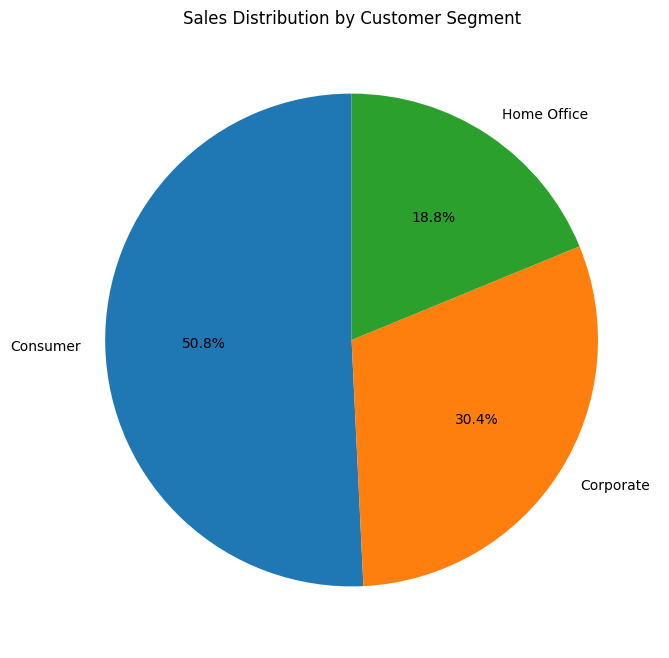

Segment
Consumer       1148061.0
Corporate       688494.0
Home Office     424982.0
Name: Sales, dtype: float64


In [91]:
#groups sales by segmentation and visualise the distribution in a pie chart
segment_sales = (sales_df.groupby('Segment')['Sales'].sum().round(0).sort_values(ascending=False))
plt.figure(figsize=(8, 8))
plt.pie(segment_sales.values, labels=segment_sales.index, autopct='%1.1f%%',startangle=90)
plt.title('Sales Distribution by Customer Segment')
plt.show()
print(segment_sales)

**Interpretation**

it can be observed that the consumer are the most significant customers and bring in the most sales.
targeted marketing can be implemented to improve the sales
new strategies need to be implemented to help corporate and home office sales.

### Monthly sales trend

Aggregate and plot the total sales per month using the Order_Date column.

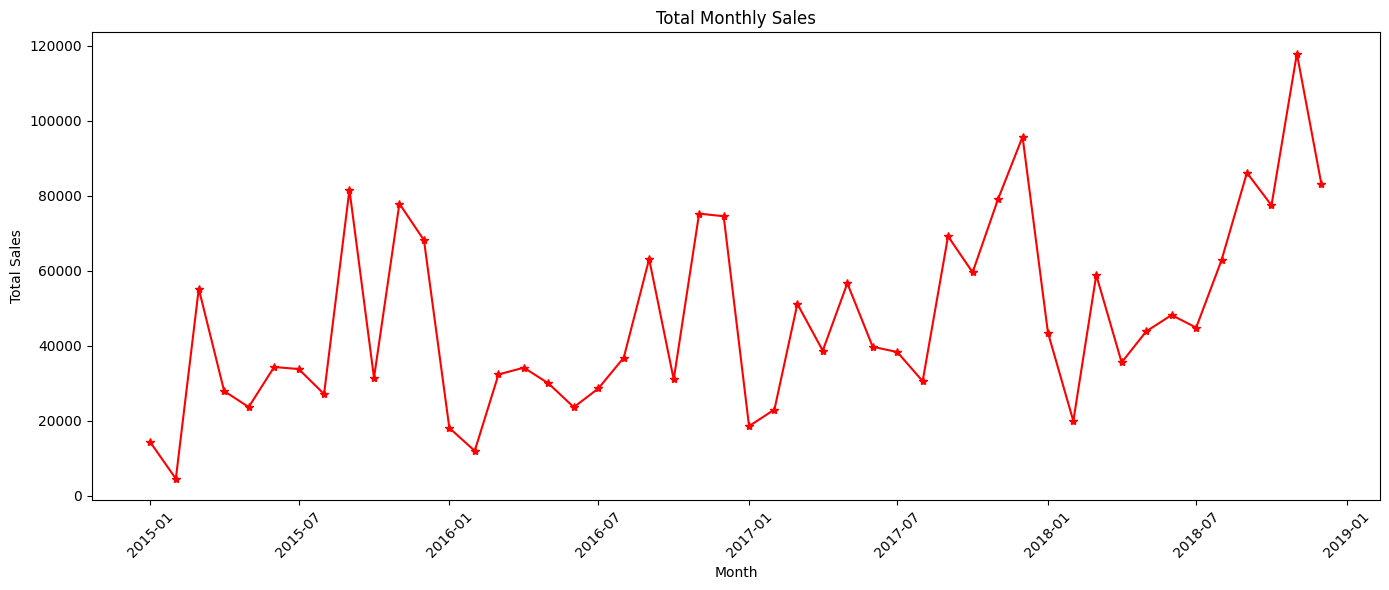

In [92]:
#groups sales by order_date per month.
monthly_sales = (sales_df.groupby(sales_df['Order_Date'].dt.to_period('M'))['Sales'].sum().reset_index())
monthly_sales['Order_Date'] = monthly_sales['Order_Date'].dt.to_timestamp()

#plots the total sales by month
plt.figure(figsize=(14, 6))
plt.plot(monthly_sales['Order_Date'], monthly_sales['Sales'], marker='*', color='red')

plt.title('Total Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Interpretations.

Sales generally increase overtime. there is variation in the number of sales per month. with peaks at the end of the year. the are patterns that indicate a time factor in the sales. seasonality.

Group and plot the total monthly sales by each category of the dataset

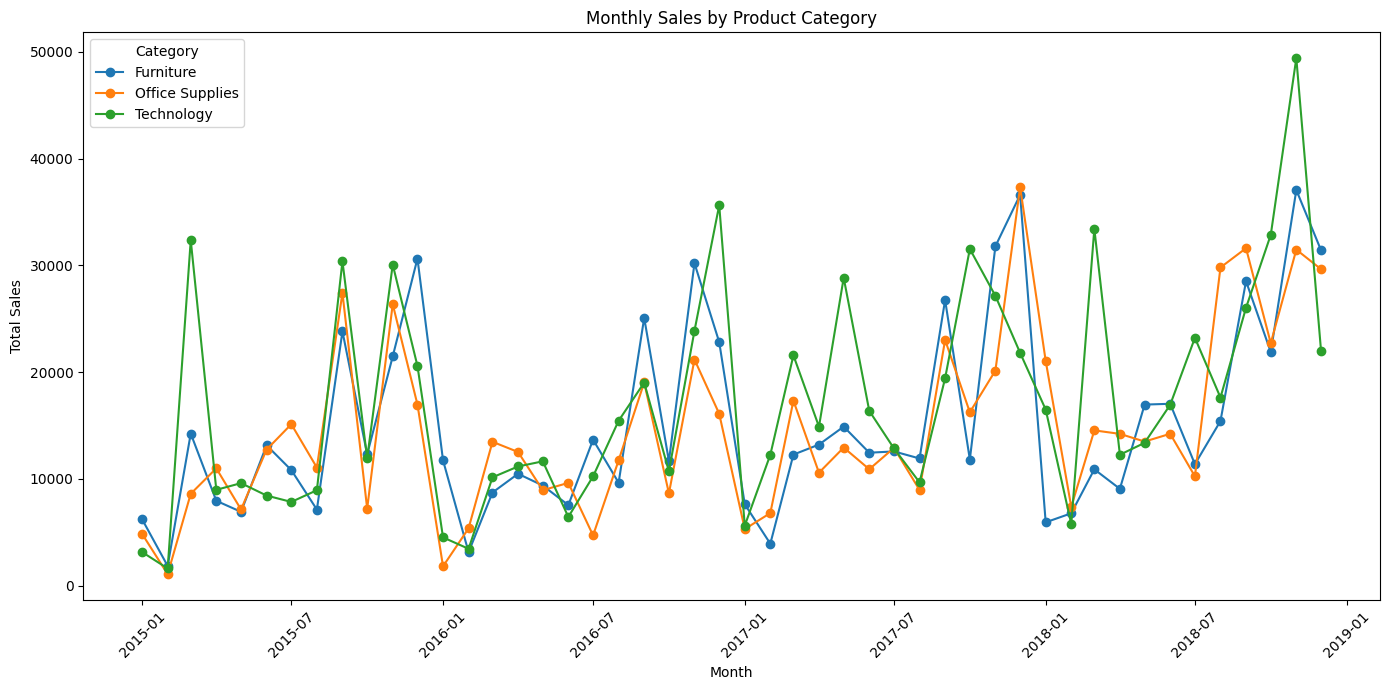

In [93]:
#groups monthly sales by category
monthly_category_sales = (sales_df.groupby([sales_df['Order_Date'].dt.to_period('M'),'Category'])['Sales'].sum().reset_index())
monthly_category_sales['Order_Date'] = (monthly_category_sales['Order_Date'].dt.to_timestamp())
plt.figure(figsize=(14, 7))

#plot for each category
for category in monthly_category_sales['Category'].unique():
    category_data = monthly_category_sales[
        monthly_category_sales['Category'] == category
    ]
    plt.plot(
        category_data['Order_Date'],
        category_data['Sales'],
        marker='o',
        label=category
    )

plt.title('Monthly Sales by Product Category')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.legend(title='Category')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Interpretation**

it can be observed that for each year there is and overal uptrend in sales. with peaks at the end of the year and lows at the begining of each year.

looking at each category, technology out performs the other categories however there are times where either office supplies or furniture out performs technology, but overall technology is the biggest in terms of sales annually. inventory and support must be of great concern during peak categorical seasons. 2018 so far is the highest the sales have been since 2015.

## Time-Series Analysis

### Decomposition of monthly sales

Decompose the monthly sales time series into its main components.

In [94]:
# Create the monthly sales time series
monthly_sales_ts = monthly_sales.set_index('Order_Date')['Sales']

#frequency is monthly
monthly_sales_ts = monthly_sales_ts.asfreq('MS')
monthly_sales_ts.head()

,Sales
Order_Date,
2015-01-01,14205.707
2015-02-01,4519.892
2015-03-01,55205.797
2015-04-01,27906.855
2015-05-01,23644.303


Decomposition

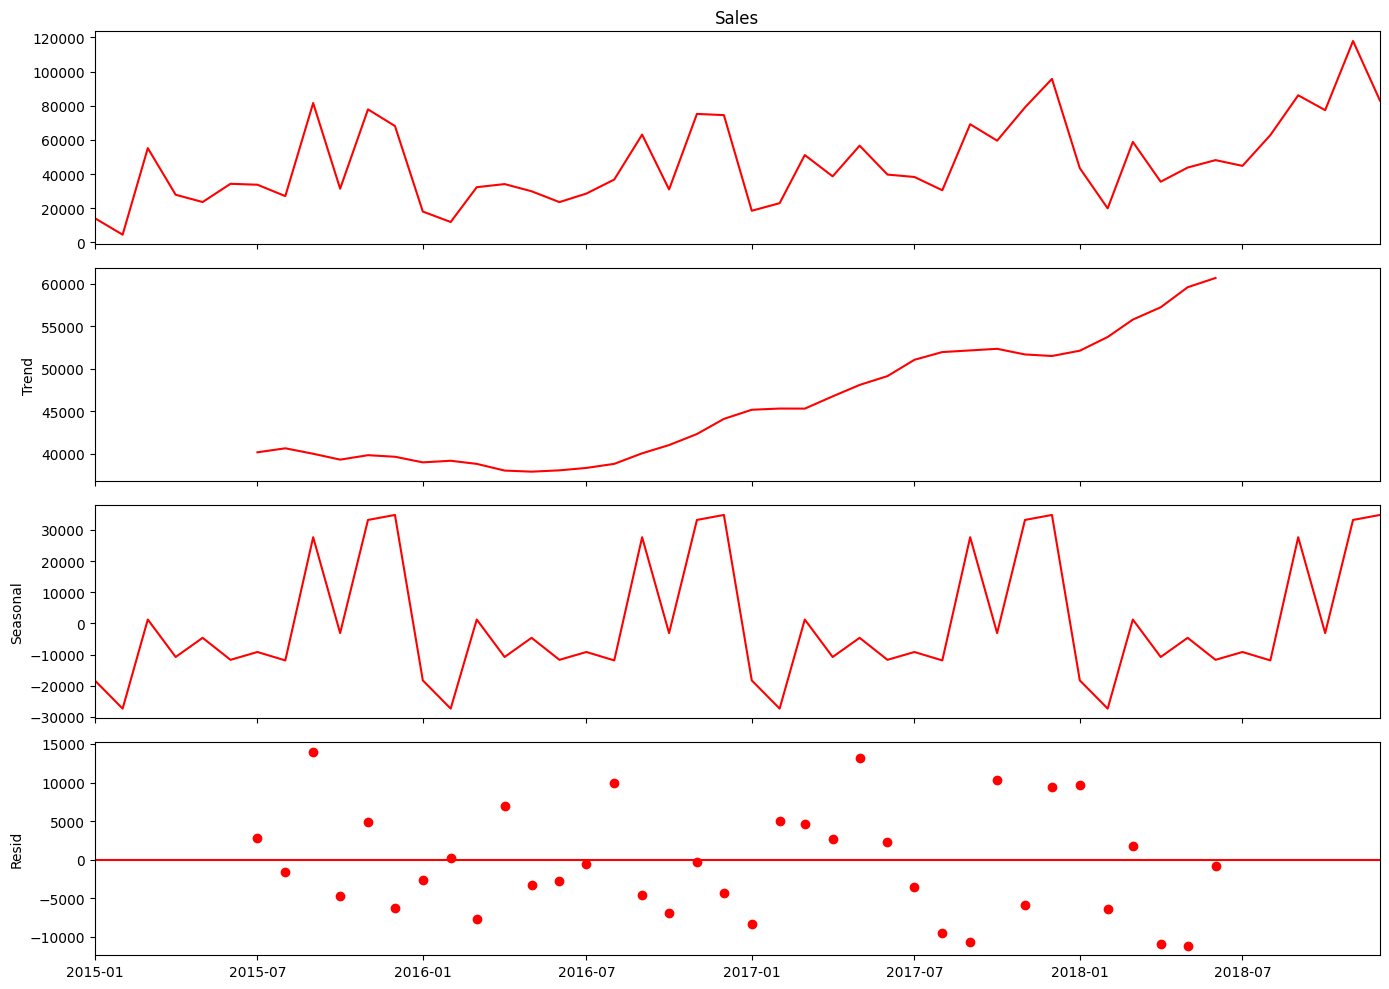

In [95]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Decompose the monthly sales time series
decomposition = seasonal_decompose(monthly_sales_ts, model='additive', period=12)

# Plot decomposition
fig = decomposition.plot()
fig.set_size_inches(14, 10)

# Make all decomposition lines red
for ax in fig.axes:
    for line in ax.get_lines():
        line.set_color('red')

plt.tight_layout()
plt.show()

Interpretation

The trend shows an overall increase or up trend in the long term.
a clear seasonal pattern is also visible. showing sales peaking high around the end of the year which may be linked  to increase consumer spending during festive seasons. sales tend to drop early each year. this indicate a recuring seasonal cycle. this seasonal component suggest that sales may be influenced by time. this regular seasonality in the festive season can be taken advantage of by the company and increase inventory and promotional campaigns during that time of the year

### ACF and PACF

Generate and interpret the ACF and PACF plots for the monthly sales time series.

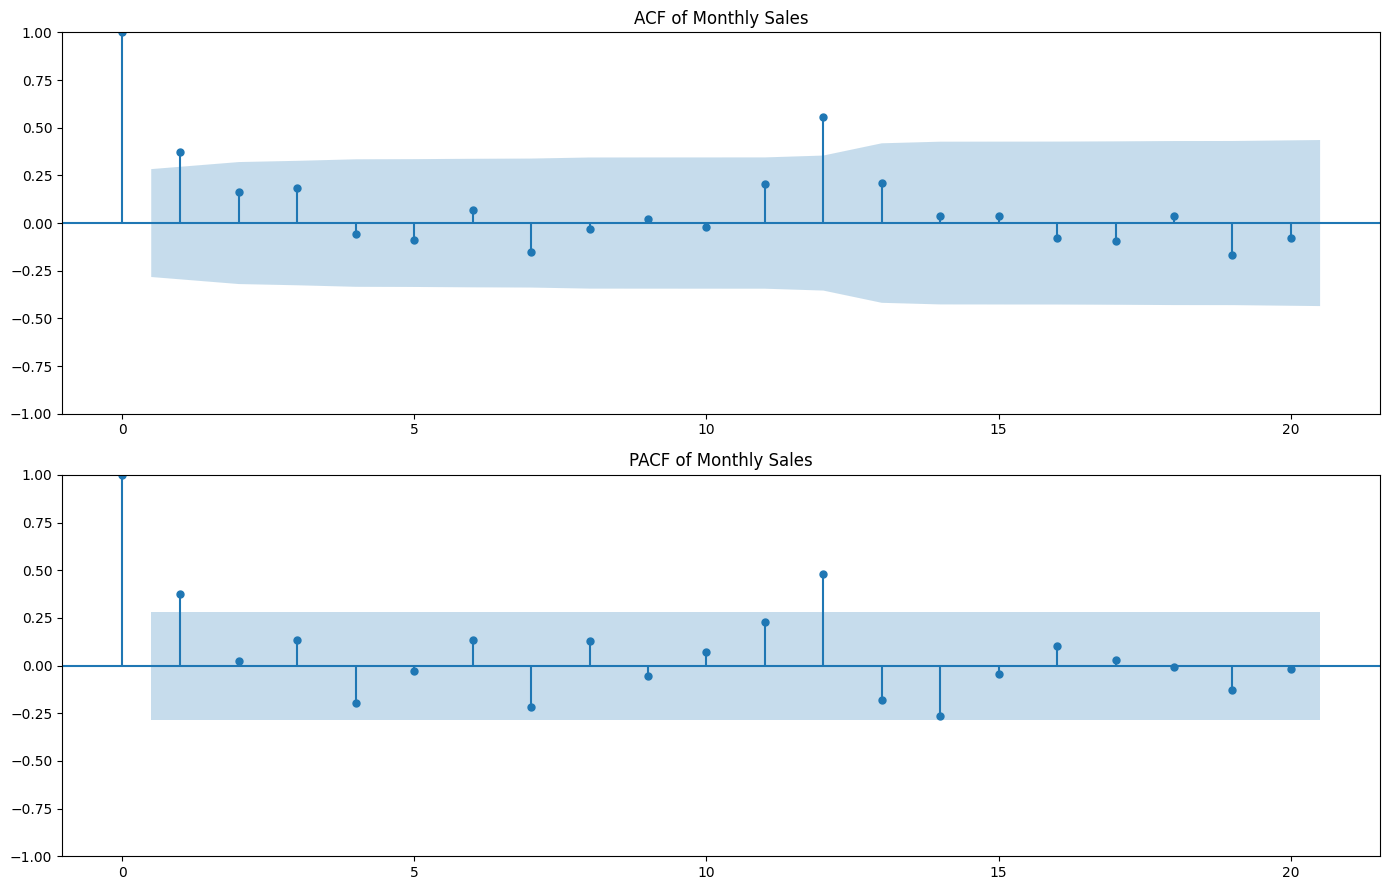

In [96]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(monthly_sales_ts, lags=20, ax=axes[0])
axes[0].set_title('ACF of Monthly Sales')

plot_pacf(monthly_sales_ts, lags=20, ax=axes[1], method='ywm')
axes[1].set_title('PACF of Monthly Sales')

plt.tight_layout()
plt.show()

**Interpretation**

The ACF plot shows significant autocorrelation at longer lags, including the 12 month lag, this indicates a relationship between the current and previous monthly sales. PACF indicate a relationship at early lags, which suggest an autoregressive behavior. looking at the correlation around the 12 month lag we can observe a possible annual seasonality. The ACF and PACF overall indicate dependance and traits of seasonality of monthly sales. based on these, AR, ARIMA and particularly SARIMA may be the approapriate models to predict current sales from previous monthly sales.

### Stationarity test (Dickey-Fuller)

Testing the stationarity of the monthly sales time series.

In [97]:
from statsmodels.tsa.stattools import adfuller

adf_test = adfuller(monthly_sales_ts)

print("ADF Statistic:", adf_test[0])
print("p-value:", adf_test[1])
print("\nCritical Values:")
for key, value in adf_test[4].items():
    print(f"{key}: {value}")

ADF Statistic: -4.416136761430769
p-value: 0.00027791039276670623

Critical Values:
1%: -3.5778480370438146
5%: -2.925338105429433
10%: -2.6007735310095064


**THE OUTPUT OF THE CODE BELOW INTERPRETES THE  DICKEY-FULLER TEST RESULTS**

In [98]:
p_value = adf_test[1]
print("INTERPRETATION OF RESULTS")
if p_value < 0.05:
    print('\n since the p-value: %f' % p_value + " is less that 0.05")
    print("\n We Reject the null hypothesis.")
    print("\n and conclude that the time series is stationary.")

else:
    print('since the p-value: %f is' % p_value + " is greater than 0.05")
    print("\n We Fail to reject the null hypothesis.")
    print("\n and conclude that The time series is non-stationary.")


INTERPRETATION OF RESULTS

 since the p-value: 0.000278 is less that 0.05

 We Reject the null hypothesis.

 and conclude that the time series is stationary.


## Forecasting Models

### Autoregressive (AR) and Moving Average (MA) models

Import forecasting Libraries

In [99]:
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA

In [100]:
# Prepare the monthly sales time series

monthly_sales_ts = monthly_sales.set_index('Order_Date')['Sales']

monthly_sales_ts = monthly_sales_ts.asfreq('MS')

monthly_sales_ts.head()

,Sales
Order_Date,
2015-01-01,14205.707
2015-02-01,4519.892
2015-03-01,55205.797
2015-04-01,27906.855
2015-05-01,23644.303


AR MODEL

In [101]:
ar_model = AutoReg(monthly_sales_ts, lags=12, trend='ct', old_names=False)

# Fitting the model then preview
ar_result = ar_model.fit()
print(ar_result.summary())

                            AutoReg Model Results                             
Dep. Variable:                  Sales   No. Observations:                   48
Model:                    AutoReg(12)   Log Likelihood                -383.043
Method:               Conditional MLE   S.D. of innovations          10108.514
Date:                Fri, 04 Sep 2026   AIC                            796.085
Time:                        12:55:43   BIC                            819.838
Sample:                    01-01-2016   HQIC                           804.376
                         - 12-01-2018                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.563e+04   1.86e+04      1.381      0.167   -1.07e+04     6.2e+04
trend       1137.3250    427.086      2.663      0.008     300.253    1974.397
Sales.L1       0.1013      0.110      0.917      0.3

Forecasting the next 12 months and ploting the AR Model

In [102]:
ar_forecast = ar_result.predict(start=len(monthly_sales_ts), end=len(monthly_sales_ts) + 11)
print("AR Forecast for the next 12 months:")
display(ar_forecast)

AR Forecast for the next 12 months:


,0
2019-01-01,54634.796126
2019-02-01,41146.687946
2019-03-01,56245.394118
2019-04-01,47582.324352
2019-05-01,53446.947069
2019-06-01,56290.318659
2019-07-01,61909.701688
2019-08-01,71015.844002
2019-09-01,96298.419470
2019-10-01,95444.920501


Moving Average model (MA)

In [103]:
# Build the Moving Average (MA) and Fit then display results
ma_model = ARIMA( monthly_sales_ts, order=(0, 0, 3), trend='ct')
ma_result = ma_model.fit()
print(ma_result.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   48
Model:                 ARIMA(0, 0, 3)   Log Likelihood                -545.314
Date:                Fri, 04 Sep 2026   AIC                           1102.628
Time:                        12:55:43   BIC                           1113.856
Sample:                    01-01-2015   HQIC                          1106.871
                         - 12-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.535e+04   8624.805      2.939      0.003    8447.394    4.23e+04
x1           888.3123    292.910      3.033      0.002     314.218    1462.406
ma.L1          0.2376      0.162      1.468      0.1

In [104]:
# Generate a 12-month MA forecast
ma_forecast = ma_result.forecast(steps=12)
print("MA Forecast for the next 12 months:")
display(ma_forecast)

MA Forecast for the next 12 months:


,predicted_mean
2019-01-01,74578.505113
2019-02-01,76454.554820
2019-03-01,70657.676389
2019-04-01,71543.938432
2019-05-01,72432.250692
2019-06-01,73320.562951
2019-07-01,74208.875210
2019-08-01,75097.187470
2019-09-01,75985.499729
2019-10-01,76873.811989


Plot the MA predicted future sales against historical sales series.

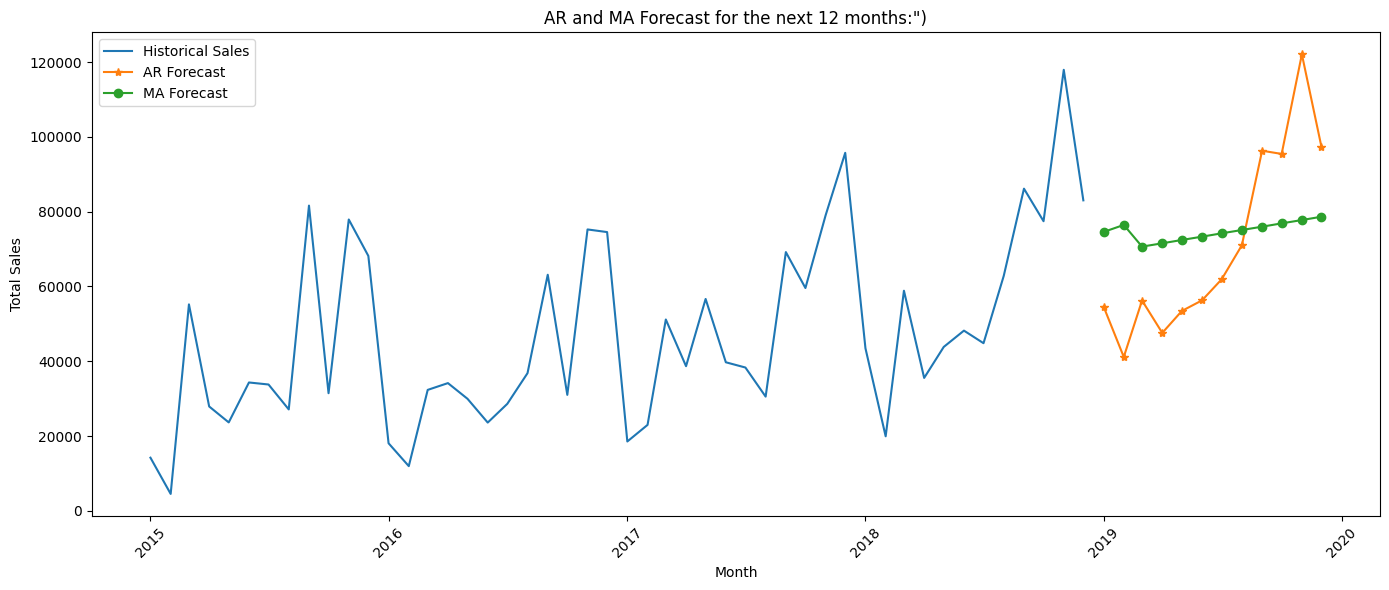

In [105]:
# Create forecast dates
forecast_index = pd.date_range(start=monthly_sales_ts.index[-1] + pd.offsets.MonthBegin(1),
    periods=12, freq='MS')

# Plot historical sales, AR forecast and MA forecast
plt.figure(figsize=(14, 6))
plt.plot(monthly_sales_ts.index, monthly_sales_ts.values, label='Historical Sales')
plt.plot(forecast_index, ar_forecast.values, marker='*', label='AR Forecast')
plt.plot(forecast_index, ma_forecast.values, marker='o', label='MA Forecast')
plt.title('AR and MA Forecast for the next 12 months:")')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretation of the AR and MA Models and future predictions**

Distinct forecasting behaviours can be observed from the two models. The AR model retains the behaviour of the previous sales series, The Forecasted series follows the pattern of the historical series, which indicate the presence of influence by the previous observations on the future sales in the AR model. The MA is more smooth and may be good for short term random shocks since it uses previous sales forecast errors.
The AR captures some seasonality due to the influence of lag 12. the MA fails to capture the seasonality observed on previous observations. both models fail to capture the strong pattern of seasonality overall.

### ARIMA model

Build an ARIMA model using the month and total sales values.

Buiding and fitting the ARIMA model

In [106]:
arima_model = ARIMA(monthly_sales_ts,order=(1, 1, 1))
# Fit the model then dispaly results
arima_result = arima_model.fit()
print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   48
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -539.293
Date:                Fri, 04 Sep 2026   AIC                           1084.585
Time:                        12:55:44   BIC                           1090.136
Sample:                    01-01-2015   HQIC                          1086.674
                         - 12-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2546      0.265      0.961      0.337      -0.265       0.774
ma.L1         -0.8477      0.144     -5.898      0.000      -1.129      -0.566
sigma2      5.791e+08   8.52e-11   6.79e+18      0.0

In [107]:
# next 12 months of forecasts
arima_forecast = arima_result.forecast(steps=12)
print("ARIMA Forecast:")
display(arima_forecast)

ARIMA Forecast:


,predicted_mean
2019-01-01,74121.351866
2019-02-01,71852.991817
2019-03-01,71275.436988
2019-04-01,71128.383798
2019-05-01,71090.942087
2019-06-01,71081.408926
2019-07-01,71078.981656
2019-08-01,71078.363641
2019-09-01,71078.206286
2019-10-01,71078.166221


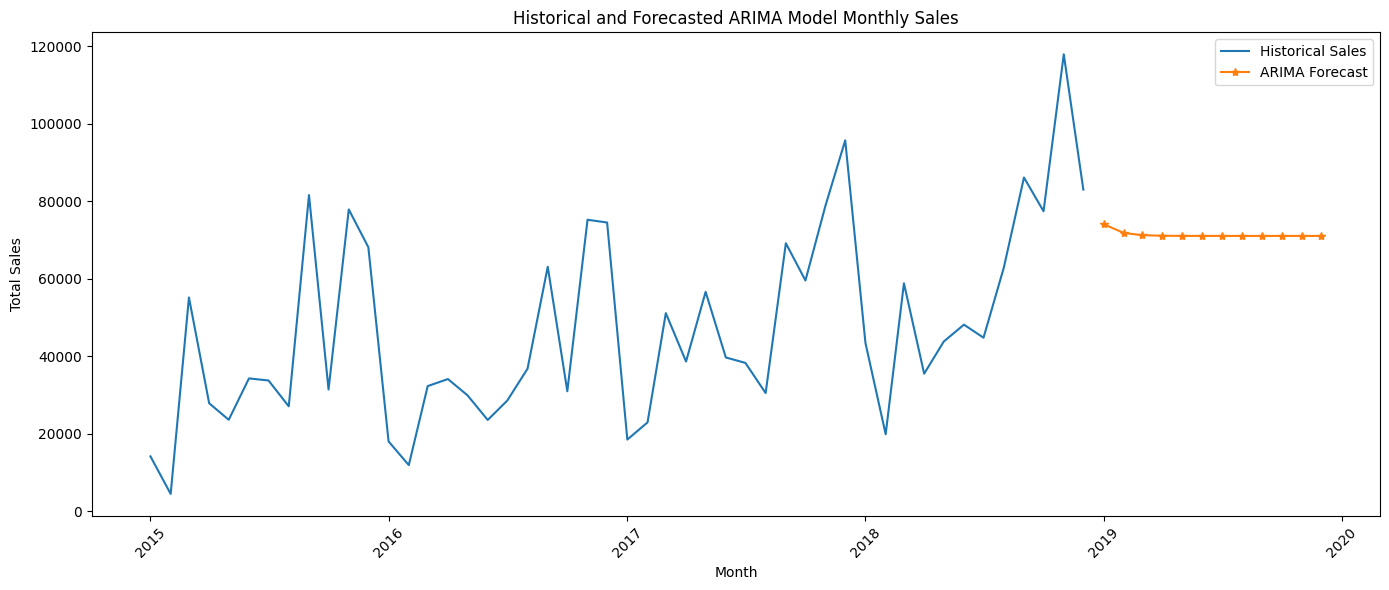

In [108]:
plt.figure(figsize=(14, 6))
plt.plot(monthly_sales_ts.index, monthly_sales_ts.values, label='Historical Sales')
plt.plot(forecast_index, arima_forecast.values, marker='*', label='ARIMA Forecast')
plt.title('Historical and Forecasted ARIMA Model Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

AR(1) is statistically not significant with p_value = 0.337 > 0.05 at 5% significance level.
MA(1) is statistically significant with p_value = -0.8477.
The AIC value (1084.585) indicates the overall model fit and can be compared with the AIC values of other ARIMA models.

The Ljung-Box test (Q = 0.30, p = 0.58) indicates no significant autocorrelation in the residuals.
The Jarque-Bera test (JB = 1.12, p = 0.57) indicates that the residuals are approximately normally distributed.

there is minimal seasonal component captured as the model does not account for seasonality. forecast shows a generally stable direction of sales. it alighns with observed sales patterns as it does not create sudden high and lows. consistent with overall sales level and direction but fails to capture seasonality.




### SARIMA model

Build a SARIMA model using the month and total sales values.

In [109]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
sarima_model = SARIMAX(monthly_sales_ts, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False)

# Fitting the model
sarima_result = sarima_model.fit(disp=False)
print(sarima_result.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Sales   No. Observations:                   48
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -229.472
Date:                            Fri, 04 Sep 2026   AIC                            468.944
Time:                                    12:55:45   BIC                            474.166
Sample:                                01-01-2015   HQIC                           470.077
                                     - 12-01-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1620      0.390      0.415      0.678      -0.602       0.926
ma.L1         -0.9150      0.176   

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning:

Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.



In [110]:
#12-month SARIMA forecast
sarima_forecast = sarima_result.forecast(steps=12)

print("SARIMA Forecast:")
display(sarima_forecast)

SARIMA Forecast:


,predicted_mean
2019-01-01,46782.479186
2019-02-01,40285.470517
2019-03-01,72234.203229
2019-04-01,57236.029426
2019-05-01,66910.825697
2019-06-01,61378.253164
2019-07-01,60193.673068
2019-08-01,64798.240306
2019-09-01,95640.888338
2019-10-01,81551.123518


Plot SARIMA Forecast

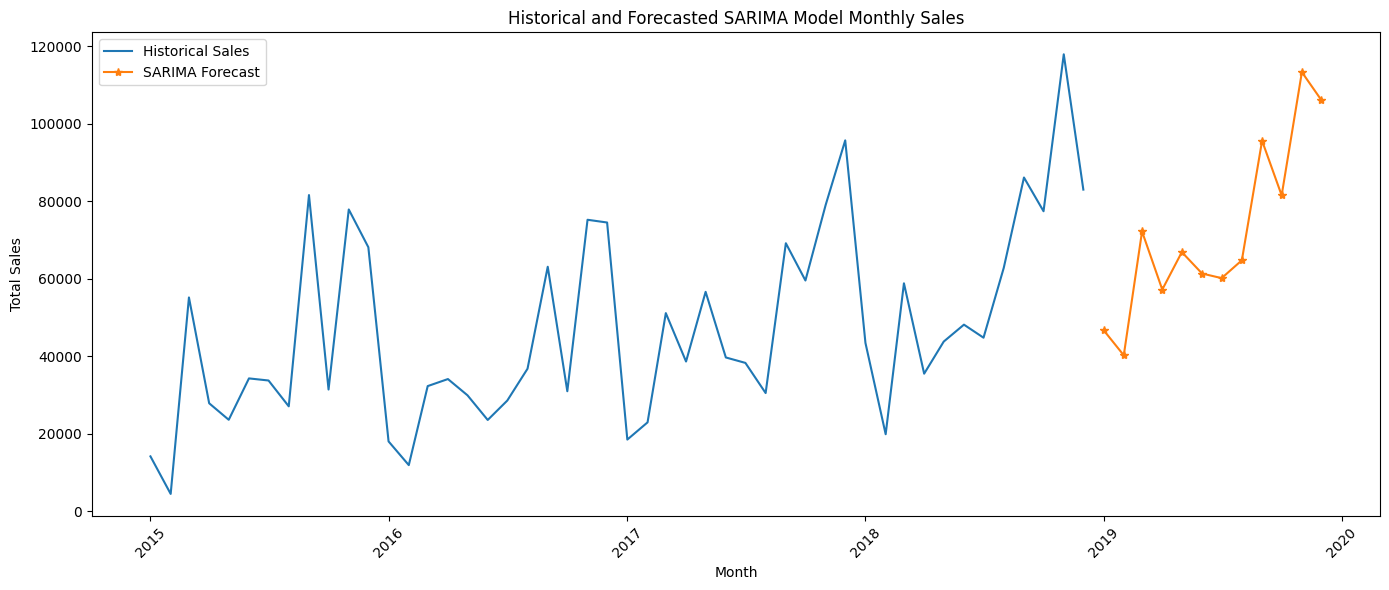

In [111]:
plt.figure(figsize=(14, 6))
plt.plot(monthly_sales_ts.index, monthly_sales_ts.values, label='Historical Sales')
plt.plot(forecast_index, sarima_forecast.values, marker='*', label='SARIMA Forecast')
plt.title('Historical and Forecasted SARIMA Model Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Interpretation:

The Ljung-Box test: Q = 0.03, p = 0.86, shows no significant autocorrelation in the residuals, this tells us that the model has adequately captured the temporal pattern in the sales data.
The Jarque-Bera test: JB = 1.52, p = 0.47 indicates that the residuals are roughly normally distributed.

The seasonal AR coefficient  and seasonal MA coefficient: -0.2720, p = 0.607, -0.3438, p = 0.386 respectively statistically insignificant. but, the lower AIC shows that including the 12-month seasonal pattern enhances the overall model fit. The model is therefore more suitable for the monthly sales series. the model accounts for both the underlying trend and the recurring 12-month seasonal pattern, which makes it the most approapriate model for predicting futures sales.

## Model Comparison and Selection

**Introduction**
The analysis of Makro’s monthly sales applied different forecasting techniques, each
of which has its characteristics, advantages and limitations in predicting future sales.
This section compares different forecasting models applied to this retail store’s sales
data, including Autoregressive (AR), Moving Average (MA), ARIMA (1,1,1), and
SARIMA (1,1,1) (1,1,1,12). It discusses the advantages, disadvantages and
suitability of each for the Makro’s monthly sales series.  
Time-Series Characteristics of the Retail Sales Data
The retails store’s monthly sales show traits that are significant in the choosing of a
suitable technique required for forecasting. The first trait that the series indicated was
non-stationarity. Using Dickey-Fuller test, it was confirmed that the series was not
stationary and required differencing. Stationary analysis for any random process
developing chronologically such as retail store sales is required (Woodward, Gray, and
Elliott, 2017). The monthly sales time series of this Makro store indicated an overall
upward trend and recurring seasonal patterns observed from the decomposition
analysis, particularly the peak during the end of the year and decline at the beginning
of each subsequent year. Hyndman and Athanasopoulos (2018) emphasize that the
identification and modelling of seasonal characteristics is important for precise
forecasting in the context of retail. It follows that the suitable forecasting model for this
retail store sales must not only account for the relationship between the current and
previous observations but also account for the trend and seasonality of the time series.  
Autoregressive (AR) Model
The AR model forecasts future sales by making use of the historical observations of
the sales series (Hyndman and Athanasopoulos, 2018). The main advantage of the
AR model is that it is can capture the relationship of previous observations to the
current series and it is relatively easy to understand and interpret. Looking at this retail
sales series, the AR model captured some seasonal variation through the 12th lag. It
gave a forecast the seemed to capture the pattern of the historical data. The limitation
of AR model is that it requires the series to be stationary. If the data is not stationary,
differencing must be applied. Another major limitation of AR is the potential risk of
overfitting (Naijil, 2025). For this retail store sales, the model appeared to be
overfitting, and the confidence intervals were relatively close which indicated
unwarranted precision and overall, many AR coefficients for this sales data were
statistically insignificant. In terms of suitability. This model partially accounted for
seasonality but failed to provide reasonable forecast for the long term because of the
unrealistic trend extrapolation and overfitting. This may be due to the non-stationarity
of the data (Woodward et al., 2017). In conclusion the AR model may be reasonable
for short term predictions, but is les appropriate for a series with seasonality as a
strong character.  
Moving Average model (MA)
The MA technique uses previous forecast errors to make predictions of future
observations. One of the major advantages of the MA model is that it can respond to
shocks and unusual movements of the data in the short-term. For this retail store, it
managed to absorb the rapid changes in the sales movements however it fails to
capture the trend and seasonality of the series. Overall the model failed to explain the
seasonal variation occurring in the sales series. In conclusion, the MA model is not
appropriate for this sales series as it struggles to capture both seasonality and trend
of the retail store.  
ARIMA model
The ARIMA model provides an technique that is stronger than the afore discussed
methods as in combines both the AR and MA methods with differencing. Differencing
in this retail store dataset is an important component as the decomposition analysis
indicated a strong trend or non-stationarity of the data. The advantage of the ARIMA
method is that is can handle data that is not stationary more effectively than simply AR
or Ma models.  The differencing component of the ARIMA method is a significant part
of, as it accounts and handles non-stationary data (Box et al., (2015). While the ARIMA
model handles better the limitations of AR and MA, It does not automatically account
for
seasonality. In this data, the Ljung-Box test indicated non-significant
autocorrelation in residuals. The ARIMA(1,1,1) model is partially suitable for the
forecasting of this retail store sales as it addresses the issue of stationarity, however
it fails to capture the strong seasonality of the data. As Guturu (2024) assert, ARIMA
models can be powerful for linear series but often come short to direct highly volatile
seasonal patterns with incorporating the seasonal components.
SARIMA model
The SARIMA model is the extention of the ARIMA model with seasonal components.
It handles the periodic patterns, making it more suitable for series with annual
seasonality. For this dataset, the SARIMA captures the seasonal pattern and the trend
while also addressing the issue of non-stationarity of the series. Because it
incorporates the AR and MA models, it accounts for previous data and current data
relationship and also the previous data forecasting errors. This model is appropriate
when the data demonstrate recurring seasonal patterns, similar to the observed retail
sales patterns. The disadvantages of this model is that the MA coefficient was
statistically insignificant and the model require complex understanding. However, the
model has shown many advantages. The AR (1) and season AR coefficient were
statistically significant. This model for this retail sales data achieved the lowest AIC
value, indicating the best fit. It captured the seasonality pattern that the other models
fail to account for. The model aligned with previous data patterns. The SARIMA model
is the most suitable for this sales series as it captures and addresses stationarity and
seasonality.
CONCLUSION
The comparative analysis has indicated that the SARIMA model is the most suitable
model in forecasting Makro’s monthly sales. The SARIMA model has accounted for
stationarity and the strong annual seasonality which the other models failed to account
or. The SARIMA also achieved the lowest AIC value, which indicate an appropriate fit.  
References
Box, G. E. P., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). Time series
analysis: Forecasting and control (5th ed.). Wiley.
Guturu, I. S. (2024). Impact of seasonality on demand forecasting techniques for
small-scale food retailers [Master's project, California State University, San
Bernardino]. CSUSB ScholarWorks
Hyndman, R. J., & Athanasopoulos, G. (2021). Forecasting: Principles and practice
(3rd ed.). OTexts.
Montgomery, D. C., Jennings, C. L., & Kulahci, M. (2015). Introduction to time series
analysis and forecasting (2nd ed.). Wiley.
Woodward, W.A., Gray, H.L. & Elliott, A.C. (2017). Applied Time Series Analysis with
R, 2nd Edition. Boca Raton, FL: CRC Press.